[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/main/notebooks/6_bures_wasserstein.ipynb)

# Bures-Wasserstein distance between geometries

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Plot the Bures-Wasserstein distance between the geometries of two models or two areas, as a function of the number k of leading eigenvectors kept (paper Fig. 6). It checks that the conclusions of Fig. 4D-E do not depend on the similarity measure.

* **Requirements**: the outputs of notebook 4 (`runs/per_image/`). A CPU is enough.

* **Time**: minutes.

<details><summary>Details</summary>

* **Distance**: the alignment of Fig. 4D-E compares only the orientation of the leading eigenvectors; `d_BW` also penalises differences in scale. For two metrics `A` and `B` with rank-`k` reconstructions `V_A diag(l_A) V_A^T` and `V_B diag(l_B) V_B^T`, `d_BW(A, B)^2 = tr(A) + tr(B) - 2 tr((A^(1/2) B A^(1/2))^(1/2))`. It is computed without forming the 4096 x 4096 matrices, for `k = 1..50` and every pair of (encoder, area) configurations, and averaged over the test images that the two configurations share.
* **Four comparisons**: V1 against V4 within Inception and within ResNet-50 (same model, different areas, dashed), and Inception against ResNet-50 within V1 and within V4 (same area, different models, solid). Left: G(x). Right: J(x).
* **What the paper reports**: for G(x) the cross-model distances (solid) lie below the cross-area distances (dashed); for J(x) the order reverses, as in Fig. 4D-E.
* The supporting functions are in `multigeom.analysis` and `multigeom.pipeline.alignment`; the plot is `figures/alignment.py`. This notebook only sets parameters and calls them.

</details>

## 1. Setup

### 1.1. Install package

On Google Colab, install `multigeom`; elsewhere this does nothing.

time: <1 sec

In [1]:
%%time

# on Google Colab install the package from PyPI, without its dependencies: Colab already
# has torch, numpy, scipy and matplotlib, and reinstalling torch is slow and can break
# the GPU runtime (nothing to do on your own machine)
import sys

if "google.colab" in sys.modules:
    %pip install -q --no-deps --pre multigeom

CPU times: user 1 μs, sys: 1 μs, total: 2 μs
Wall time: 2.38 μs


### 1.2. Inputs

The distances use the per-image eigenvectors and eigenvalues in `runs/per_image/`, estimated by notebook 4 (`4_subspace_alignment.ipynb`). At least two configurations are needed; all four comparisons need Inception and ResNet-50 for both V1 and V4.

<details><summary>Details</summary>

The paper averages over 200 test images and all configurations; with fewer images the curves are noisier.

</details>

time: <1 sec

In [2]:
%%time

# import built-in packages
import os, sys
from pathlib import Path
import importlib

# move to the repository root (the folder containing environment.yml): data/ and runs/
# are read from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

sys.path.insert(0, str(root))  # the figures/ folder of this repository

# import custom packages
from multigeom.utils import show_figure
from figures.alignment import plot_bures_wasserstein
from multigeom.pipeline import alignment as bw

importlib.reload(bw)  # update the module without restarting the kernel

# parameters
# folder with per_image/<encoder>/<area>/img*.pt (written by notebook 4)
RUNS_DIR = "runs"

# which per-image files exist for each configuration
summary = bw.print_inputs(RUNS_DIR)

inception  V1: 200 images
inception  V4: 200 images
resnet50   V1: 200 images
resnet50   V4: 200 images
fewest images shared by two configurations: 200
CPU times: user 3.05 s, sys: 88.7 ms, total: 3.14 s
Wall time: 635 ms


## 2. The distances

Runs `multigeom.pipeline.alignment` (minutes at most, on the CPU) and writes `runs/metrics/cross_encoder_metrics.json`, which also holds the subspace alignment of Fig. 4D-E. It does nothing if fewer than two configurations have per-image files.

time: 1 sec

In [3]:
%%time

# distances between every pair of configurations, saved as JSON
metrics_path = bw.compute_metrics(RUNS_DIR, out_dir=f"{RUNS_DIR}/metrics")

[Stage 5] Found 4 (encoder, area) configs:
     inception / V1: 200 images
     inception / V4: 200 images
      resnet50 / V1: 200 images
      resnet50 / V4: 200 images
[Stage 5] Saved 12 pairwise comparisons to runs/metrics/cross_encoder_metrics.json

[Stage 5] Paper comparisons (mean over images):
  cross_area_inception__G                       A_20 = 0.509 ± 0.004   d_BW(k=20) = 1.37   n = 200
  cross_area_inception__J                       A_20 = 0.349 ± 0.003   d_BW(k=20) = 29.4   n = 200
  cross_area_resnet50__G                        A_20 = 0.510 ± 0.004   d_BW(k=20) = 1.28   n = 200
  cross_area_resnet50__J                        A_20 = 0.261 ± 0.003   d_BW(k=20) = 42.1   n = 200
  cross_model_V1_inception_resnet50__G          A_20 = 0.794 ± 0.002   d_BW(k=20) = 0.595   n = 200
  cross_model_V1_inception_resnet50__J          A_20 = 0.146 ± 0.002   d_BW(k=20) = 47.9   n = 200
  cross_model_V4_inception_resnet50__G          A_20 = 0.816 ± 0.002   d_BW(k=20) = 0.722   n = 200
  

## 3. Does the order match the paper?

The mean of `d_BW` over `k` for the two cross-model comparisons and the two cross-area comparisons, for each metric. The paper reports cross-model below cross-area for G(x) and the reverse for J(x).

time: <1 sec

In [4]:
%%time

# mean distance over k: cross-model against cross-area, for each metric
if metrics_path is None:
    print(
        "Nothing to check yet: the alignment needs at least two configurations "
        "(see "
        "the message above)."
    )
else:
    metrics = bw.load_metrics(metrics_path)
    order = bw.print_ordering(metrics)

G: mean d_BW over k: cross-model 0.648, cross-area 1.29  -> paper expects cross-model below cross-area: yes
J: mean d_BW over k: cross-model 42.7, cross-area 35  -> paper expects cross-model above cross-area: yes
CPU times: user 634 μs, sys: 0 ns, total: 634 μs
Wall time: 953 μs


## 4. Plot Fig. 6

Solid: different models, same area. Dashed: the same model, V1 versus V4. Bands: s.e.m. across the images. The paper also compares ON-OFF, for which there are no checkpoints here.

time: <1 sec

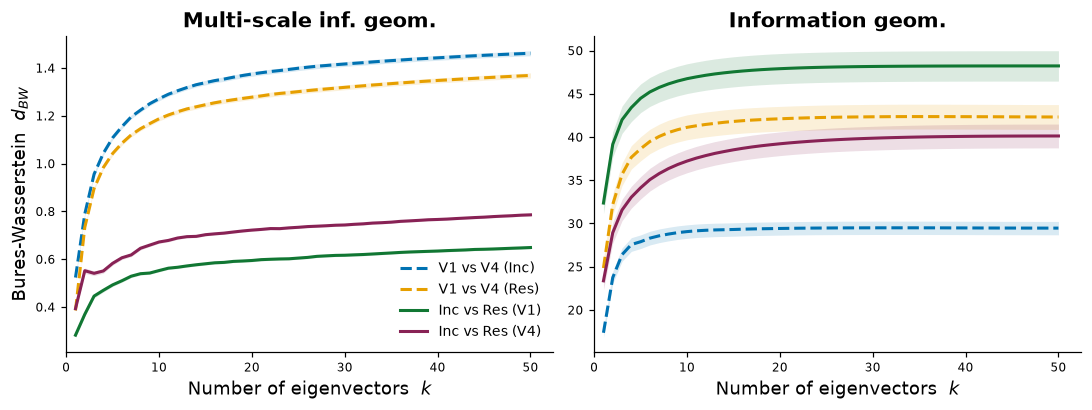

CPU times: user 322 ms, sys: 15 ms, total: 337 ms
Wall time: 337 ms


In [5]:
%%time

# Bures-Wasserstein distance against k, for the four comparisons
if metrics_path is None:
    print("Nothing to plot yet: run the cells above first.")
else:
    show_figure(plot_bures_wasserstein(metrics))